In [54]:
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from keras.datasets import mnist
from keras import models
from keras.layers import Input, Flatten, Conv2D, MaxPooling2D, AveragePooling2D, GlobalAveragePooling2D, GlobalMaxPooling2D, ReLU, Dense, BatchNormalization

# Without Pooling

In [55]:
inputs = Input((28, 28, 1))
conv1  = Conv2D(8, 3, padding="valid", name="conv1")(inputs)
relu1  = ReLU(name="relu1")(conv1)
conv2  = Conv2D(16, 3, padding="valid", name="conv2")(relu1)
relu2  = ReLU(name="relu2")(conv2)
flat = Flatten()(relu2)
out = Dense(1000, activation='relu')(flat)

names = ["conv1", "relu1", "conv2", "relu2"]
tensors = [conv1, relu1, conv2, relu2, flat, out]
probe = models.Model(inputs, tensors) 

probe.summary()

Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_24 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 26, 26, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 24, 24, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 24, 24, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1000)           │     9,217,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,218,248 (35.16 MB)

 Trainable params: 9,218,248 (35.16 MB)

 Non-trainable params: 0 (0.00 B)

# With Pooling Layer

In [ ]:
inputs = Input((28, 28, 1))
conv1  = Conv2D(8, 3, padding="valid", name="conv1")(inputs)
relu1  = ReLU(name="relu1")(conv1)
pool1  = MaxPooling2D(2, name="pool1")(relu1)
conv2  = Conv2D(16, 3, padding="valid", name="conv2")(pool1)
relu2  = ReLU(name="relu2")(conv2)
pool2 = GlobalMaxPooling2D(name = 'pool2')(relu2)
out = Dense(1000, activation='relu')(pool2)

tensors = [conv1, relu1, pool1, conv2, relu2, pool2, out]
probe = models.Model(inputs, tensors) 
probe.summary()

Model: "functional_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_27 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 26, 26, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 11, 11, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (GlobalMaxPooling2D)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1000)           │        17,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,248 (71.28 KB)

 Trainable params: 18,248 (71.28 KB)

 Non-trainable params: 0 (0.00 B)

Raw digit: (28, 28) | label: 5


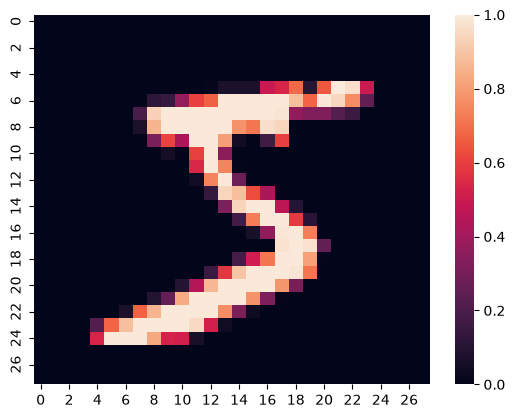

In [32]:
# 1. Load MNIST and pick one digit
(x_train, y_train), _ = mnist.load_data()
digit = x_train[0].astype("float32") / 255.0          # (28, 28)
print("Raw digit:", digit.shape, "| label:", y_train[0])

sns.heatmap(digit)
plt.show()

# 1. MaxPooling

In [37]:
# 2. Keras Conv2D expects (batch, height, width, channels)
x = digit[np.newaxis, :, :, np.newaxis]               # (1, 28, 28, 1)
print("Model input:", x.shape)

# 3. Build the layers, each exposed as its own output
inputs = Input((28, 28, 1))
conv1  = Conv2D(8, 3, padding="valid", name="conv1")(inputs)
relu1  = ReLU(name="relu1")(conv1)
pool1  = MaxPooling2D(2, name="pool1")(relu1)
conv2  = Conv2D(16, 3, padding="valid", name="conv2")(pool1)
relu2  = ReLU(name="relu2")(conv2)
pool2  = MaxPooling2D(2, name="pool2")(relu2)

names = ["conv1", "relu1", "pool1", "conv2", "relu2", "pool2"]
tensors = [conv1, relu1, pool1, conv2, relu2, pool2]
probe = models.Model(inputs, tensors)                 # returns every stage at once
outs = probe.predict(x, verbose=0)

# 4. Print how the shape changes at each stage
print(f"\n{'stage':<8}{'output shape'}")
print(f"{'input':<8}{x.shape}")
for name, o in zip(names, outs):
    print(f"{name:<8}{o.shape}")

probe.summary()

Model input: (1, 28, 28, 1)

stage   output shape
input   (1, 28, 28, 1)
conv1   (1, 26, 26, 8)
relu1   (1, 26, 26, 8)
pool1   (1, 13, 13, 8)
conv2   (1, 11, 11, 16)
relu2   (1, 11, 11, 16)
pool2   (1, 5, 5, 16)


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 26, 26, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 11, 11, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 5, 5, 16)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,248 (4.88 KB)

 Trainable params: 1,248 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

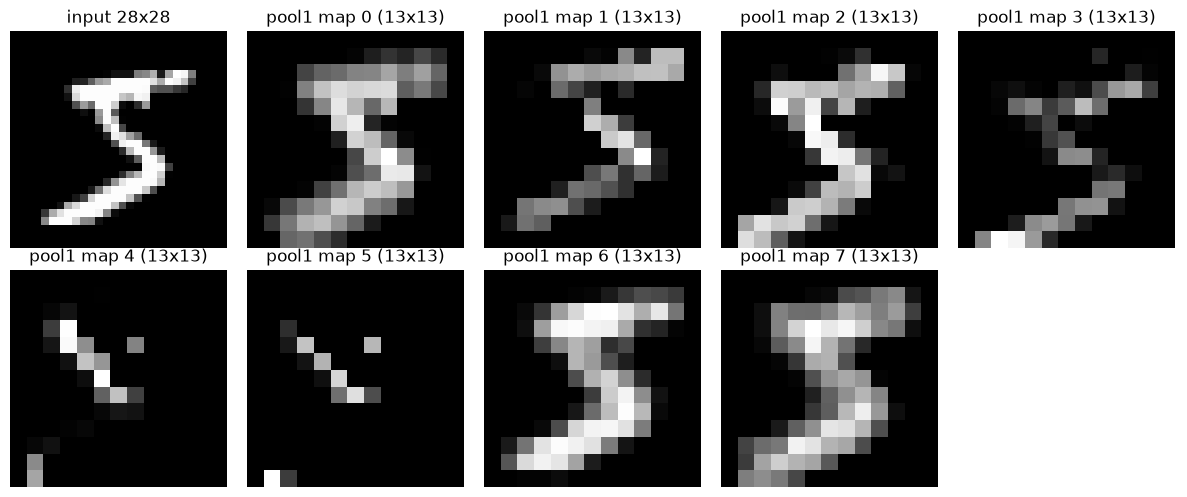

In [38]:
# 5. Visualize: original digit + 8 feature maps after pool1
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(digit, cmap="gray"); axes[0, 0].set_title("input 28x28")
for i in range(8):
    ax = axes[(i + 1) // 5, (i + 1) % 5]
    ax.imshow(outs[2][0, :, :, i], cmap="gray")       # outs[2] = pool1
    ax.set_title(f"pool1 map {i} (13x13)")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

# 2. AvgPooling

In [39]:
# 2. Keras Conv2D expects (batch, height, width, channels)
x = digit[np.newaxis, :, :, np.newaxis]               # (1, 28, 28, 1)
print("Model input:", x.shape)

# 3. Build the layers, each exposed as its own output
inputs = Input((28, 28, 1))
conv1  = Conv2D(8, 3, padding="valid", name="conv1")(inputs)
relu1  = ReLU(name="relu1")(conv1)
pool1  = AveragePooling2D(2, name="pool1")(relu1)
conv2  = Conv2D(16, 3, padding="valid", name="conv2")(pool1)
relu2  = ReLU(name="relu2")(conv2)
pool2  = AveragePooling2D(2, name="pool2")(relu2)

names = ["conv1", "relu1", "pool1", "conv2", "relu2", "pool2"]
tensors = [conv1, relu1, pool1, conv2, relu2, pool2]
probe = models.Model(inputs, tensors)                 # returns every stage at once
outs = probe.predict(x, verbose=0)

# 4. Print how the shape changes at each stage
print(f"\n{'stage':<8}{'output shape'}")
print(f"{'input':<8}{x.shape}")
for name, o in zip(names, outs):
    print(f"{name:<8}{o.shape}")

probe.summary()

Model input: (1, 28, 28, 1)

stage   output shape
input   (1, 28, 28, 1)
conv1   (1, 26, 26, 8)
relu1   (1, 26, 26, 8)
pool1   (1, 13, 13, 8)
conv2   (1, 11, 11, 16)
relu2   (1, 11, 11, 16)
pool2   (1, 5, 5, 16)


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 26, 26, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (AveragePooling2D)        │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 11, 11, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (AveragePooling2D)        │ (None, 5, 5, 16)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,248 (4.88 KB)

 Trainable params: 1,248 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

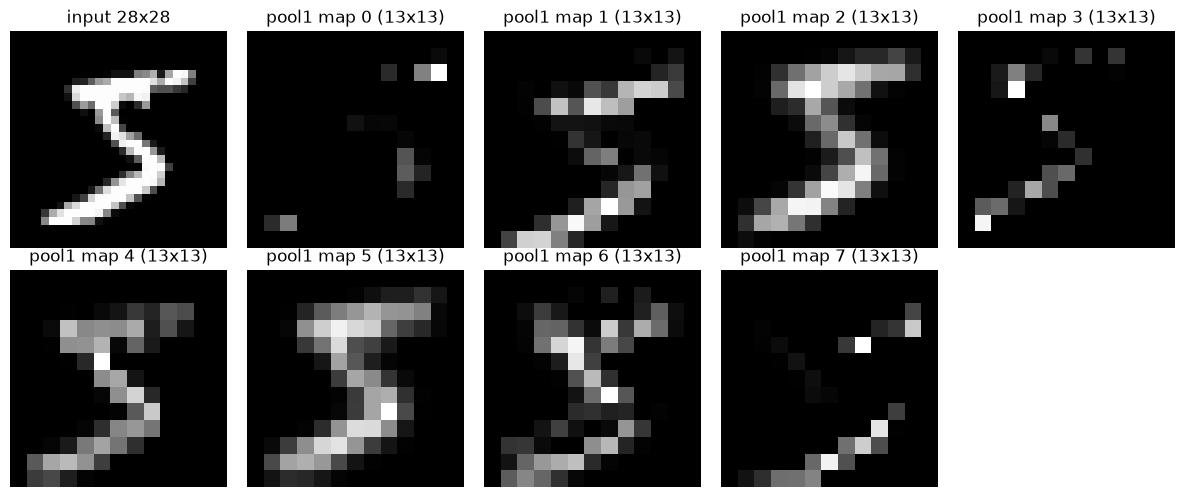

In [40]:
# 5. Visualize: original digit + 8 feature maps after pool1
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(digit, cmap="gray"); axes[0, 0].set_title("input 28x28")
for i in range(8):
    ax = axes[(i + 1) // 5, (i + 1) % 5]
    ax.imshow(outs[2][0, :, :, i], cmap="gray")       # outs[2] = pool1
    ax.set_title(f"pool1 map {i} (13x13)")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

# 3. Global Avg Pooling

In [42]:
# 2. Keras Conv2D expects (batch, height, width, channels)
x = digit[np.newaxis, :, :, np.newaxis]               # (1, 28, 28, 1)
print("Model input:", x.shape)

# 3. Build the layers, each exposed as its own output
inputs = Input((28, 28, 1))
conv1  = Conv2D(8, 3, padding="valid", name="conv1")(inputs)
relu1  = ReLU(name="relu1")(conv1)
pool1  = MaxPooling2D(2, name="pool1")(relu1)
conv2  = Conv2D(16, 3, padding="valid", name="conv2")(pool1)
relu2  = ReLU(name="relu2")(conv2)
pool2  = GlobalAveragePooling2D()(relu2)

names = ["conv1", "relu1", "pool1", "conv2", "relu2", "pool2"]
tensors = [conv1, relu1, pool1, conv2, relu2, pool2]
probe = models.Model(inputs, tensors)                 # returns every stage at once
outs = probe.predict(x, verbose=0)

# 4. Print how the shape changes at each stage
print(f"\n{'stage':<8}{'output shape'}")
print(f"{'input':<8}{x.shape}")
for name, o in zip(names, outs):
    print(f"{name:<8}{o.shape}")

probe.summary()

Model input: (1, 28, 28, 1)

stage   output shape
input   (1, 28, 28, 1)
conv1   (1, 26, 26, 8)
relu1   (1, 26, 26, 8)
pool1   (1, 13, 13, 8)
conv2   (1, 11, 11, 16)
relu2   (1, 11, 11, 16)
pool2   (1, 16)


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 26, 26, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 11, 11, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,248 (4.88 KB)

 Trainable params: 1,248 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

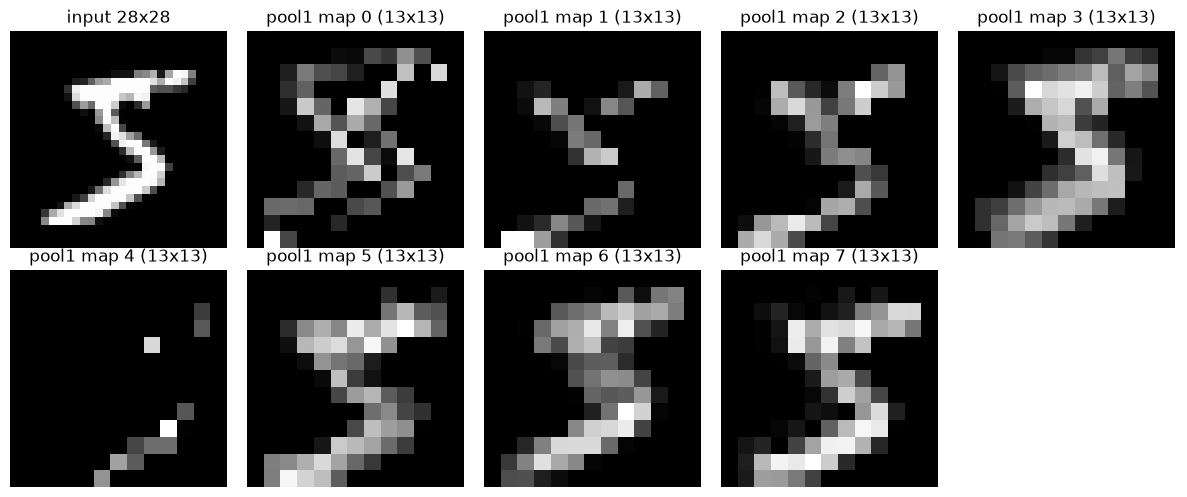

In [43]:
# 5. Visualize: original digit + 8 feature maps after pool1
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(digit, cmap="gray"); axes[0, 0].set_title("input 28x28")
for i in range(8):
    ax = axes[(i + 1) // 5, (i + 1) % 5]
    ax.imshow(outs[2][0, :, :, i], cmap="gray")       # outs[2] = pool1
    ax.set_title(f"pool1 map {i} (13x13)")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

# 4. Global Max Pooling

In [45]:
# 2. Keras Conv2D expects (batch, height, width, channels)
x = digit[np.newaxis, :, :, np.newaxis]               # (1, 28, 28, 1)
print("Model input:", x.shape)

# 3. Build the layers, each exposed as its own output
inputs = Input((28, 28, 1))
conv1  = Conv2D(8, 3, padding="valid", name="conv1")(inputs)
relu1  = ReLU(name="relu1")(conv1)
pool1  = MaxPooling2D(2, name="pool1")(relu1)
conv2  = Conv2D(16, 3, padding="valid", name="conv2")(pool1)
relu2  = ReLU(name="relu2")(conv2)
pool2  = GlobalMaxPooling2D()(relu2)

names = ["conv1", "relu1", "pool1", "conv2", "relu2", "pool2"]
tensors = [conv1, relu1, pool1, conv2, relu2, pool2]
probe = models.Model(inputs, tensors)                 # returns every stage at once
outs = probe.predict(x, verbose=0)

# 4. Print how the shape changes at each stage
print(f"\n{'stage':<8}{'output shape'}")
print(f"{'input':<8}{x.shape}")
for name, o in zip(names, outs):
    print(f"{name:<8}{o.shape}")

probe.summary()

Model input: (1, 28, 28, 1)

stage   output shape
input   (1, 28, 28, 1)
conv1   (1, 26, 26, 8)
relu1   (1, 26, 26, 8)
pool1   (1, 13, 13, 8)
conv2   (1, 11, 11, 16)
relu2   (1, 11, 11, 16)
pool2   (1, 16)


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 26, 26, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 11, 11, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 16)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,248 (4.88 KB)

 Trainable params: 1,248 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

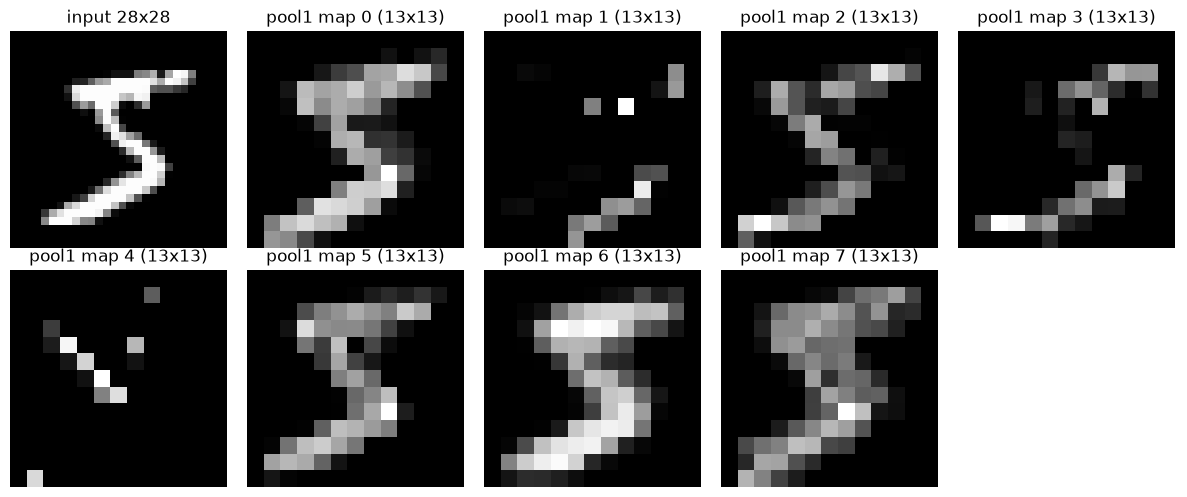

In [46]:
# 5. Visualize: original digit + 8 feature maps after pool1
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(digit, cmap="gray"); axes[0, 0].set_title("input 28x28")
for i in range(8):
    ax = axes[(i + 1) // 5, (i + 1) % 5]
    ax.imshow(outs[2][0, :, :, i], cmap="gray")       # outs[2] = pool1
    ax.set_title(f"pool1 map {i} (13x13)")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

# Full CNN Block : `Conv` → `BatchNorm` → `ReLU` → `Pool`

In [ ]:
def conv_block(x, filters):
    x = Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = MaxPooling2D(2)(x)
    return x

inputs = Input((228, 228, 3))               # (228,228,3) RGB Image
x = conv_block(inputs, 32)                  # (228,228,3) -> (114, 114, 32)
x = conv_block(x, 64)                       # (114, 114, 32) -> (57, 57, 64) 
x = conv_block(x, 128)                      # (57, 57, 64) -> (28, 28, 128)
x = GlobalAveragePooling2D()(x)             # (28, 28, 128) -> (128,)
outputs = Dense(10, activation="softmax")(x)
model = models.Model(inputs, outputs)